# Controller comparison: 2-way single intersection

Reads the raw logs written by `experiments/clm_2way-single-intersection.py`
(one folder per invocation in `outputs/2way-single-intersection/`) and compares controllers per lane.

**Delay per vehicle** = time stopped at the intersection (`waiting_time`) + time spent waiting to enter the
network because its entry lane was full (`depart_delay`). Vehicles that never entered or never finished are included.
Set `METRIC` below to look at either part on its own.

Q-learning trains across the runs of one invocation (`-runs`); its last run is greedy, and that is the run compared here
(`RUN = -1`). The learning curve at the end shows every run.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd() if (Path.cwd() / "outputs").exists() else Path.cwd().parent
RUNS_DIR = ROOT / "outputs" / "2way-single-intersection"

RUN_FOLDERS = None  # None = latest folder per controller, or e.g. ["2026-09-27_18-13-32_maxpressure", ...]
RUN = -1  # which run inside a folder with -runs > 1 (-1 = last)
METRIC = "total_delay"  # or "waiting_time" (stopped at the intersection) / "depart_delay" (waiting to enter)
PERCENTILES = [50, 75, 90, 95, 99]

# One fixed colour per controller (validated categorical slots), never re-assigned by rank or filter
CONTROLLERS = {
    "maxpressure": ("Max-pressure", "#2a78d6"),
    "fixed": ("Fixed-time", "#eb6834"),
    "clm": ("CLM-8B", "#1baf7a"),
    "ql": ("Q-learning", "#eda100"),
}
SURFACE, INK, INK_2, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0"
BLUE_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
             "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "figure.dpi": 110,
})


def name(agent):
    return CONTROLLERS.get(agent, (agent, INK_MUTED))[0]


def color(agent):
    return CONTROLLERS.get(agent, (agent, INK_MUTED))[1]


def end_labels(ax, items, min_gap=13):
    # End dot + direct label for each (x, y, text, colour), nudged apart vertically so labels never overlap
    ax.get_ylim()  # settle autoscaling before measuring
    items = sorted(items, key=lambda item: item[1])
    to_points = 72 / ax.figure.dpi
    ys = [ax.transData.transform((x, y))[1] * to_points for x, y, _, _ in items]
    placed = []
    for y in ys:
        placed.append(max(y, placed[-1] + min_gap) if placed else y)
    for (x, y, text, c), y0, y1 in zip(items, ys, placed):
        ax.scatter(x, y, s=64, color=c, edgecolors=SURFACE, linewidths=2, zorder=3, clip_on=False)
        ax.annotate(text, (x, y), xytext=(8, y1 - y0), textcoords="offset points", va="center", fontsize=9,
                    color=INK_2, annotation_clip=False)

## Load runs

In [2]:
def find_runs():
    if RUN_FOLDERS is not None:
        folders = [RUNS_DIR / f for f in RUN_FOLDERS]
    else:
        folders = sorted(d for d in RUNS_DIR.iterdir() if (d / "meta.json").exists())  # names start with the time
    runs = {}
    for d in folders:
        runs[json.loads((d / "meta.json").read_text())["args"]["agent"]] = d  # later folders win
    order = [a for a in CONTROLLERS if a in runs] + [a for a in runs if a not in CONTROLLERS]
    return {a: runs[a] for a in order}


def load(agent, folder):
    meta = json.loads((folder / "meta.json").read_text())
    lane_names = {lane: n for s in meta["signals"].values() for lane, n in s["lanes"].items()}
    phase_names = {i: n for s in meta["signals"].values() for i, n in enumerate(s["phases"])}
    tables = {}
    for table in ["vehicles", "lanes", "signals"]:
        df = pd.read_csv(folder / f"{table}.csv")
        tables[table] = df[df["run"] == sorted(df["run"].unique())[RUN]].assign(controller=agent)
    tables["vehicles"]["lane_name"] = tables["vehicles"]["lane"].map(lane_names)
    tables["lanes"]["lane_name"] = tables["lanes"]["lane"].map(lane_names)
    tables["signals"]["phase_name"] = tables["signals"]["green_phase"].map(phase_names).fillna("Yellow (switching)")
    episodes = sorted(folder.glob("metrics_*_ep*.csv"), key=lambda f: int(f.stem.split("_ep")[-1]))
    tables["metrics"] = pd.read_csv(episodes[RUN]).assign(controller=agent)
    return tables, meta, list(lane_names.values()), list(phase_names.values())


runs = find_runs()
loaded = {a: load(a, d) for a, d in runs.items()}
AGENTS = list(runs)
vehicles, lanes, signals, metrics = (pd.concat(loaded[a][0][t] for a in AGENTS) for t in ["vehicles", "lanes", "signals", "metrics"])
LANE_ORDER, PHASE_ORDER = loaded[AGENTS[0]][2], loaded[AGENTS[0]][3]
pd.DataFrame({"folder": [d.name for d in runs.values()], "simulated seconds": [loaded[a][1]["args"]["seconds"] for a in AGENTS]},
             index=[name(a) for a in AGENTS])

,folder,simulated seconds
Max-pressure,2026-09-27_18-13-32_maxpressure,3000
Fixed-time,2026-09-27_18-13-40_fixed,3000
CLM-8B,2026-09-27_18-13-52_clm,3000
Q-learning,2026-09-27_18-21-54_ql,3000


## Overall delay per vehicle

`never entered`: vehicles still waiting to enter the network when the simulation ended.
`still on road`: entered but had not left the intersection area by the end.

In [3]:
def summary(df):
    x = df[METRIC]
    row = {"vehicles": len(df), "never entered": (~df["entered"]).sum(),
           "still on road": (df["entered"] & ~df["finished"]).sum(), "mean": x.mean()}
    row.update({f"p{p}": np.percentile(x, p) for p in PERCENTILES})
    row["max"] = x.max()
    return pd.Series(row)


overall = pd.DataFrame({name(a): summary(vehicles[vehicles["controller"] == a]) for a in AGENTS}).T
overall.style.format("{:,.0f}", subset=["vehicles", "never entered", "still on road"]).format(
    "{:,.1f}", subset=["mean"] + [f"p{p}" for p in PERCENTILES] + ["max"])

,vehicles,never entered,still on road,mean,p50,p75,p90,p95,p99,max
Max-pressure,"2,088",0,28,17.1,9.0,19.0,41.0,68.0,159.1,237.0
Fixed-time,"2,088",283,68,241.8,31.2,51.9,"1,082.4","1,500.0","1,787.0","1,881.0"
CLM-8B,"2,088",806,122,664.4,1.8,"1,308.0","2,328.0","2,673.3","2,929.1","2,988.0"
Q-learning,"2,088",20,73,80.6,10.5,45.0,173.0,255.3,"1,598.0","2,030.0"


## Delay per lane

In [4]:
per_lane = pd.concat(
    {f"p{p}": vehicles.groupby(["lane_name", "controller"])[METRIC].quantile(p / 100).unstack("controller")
     for p in [50, 90, 95, 99]}, axis=1)
per_lane = per_lane.reindex(LANE_ORDER)
per_lane.columns = pd.MultiIndex.from_tuples([(p, name(a)) for p, a in per_lane.columns])
per_lane = per_lane[[(p, name(a)) for p in ["p50", "p90", "p95", "p99"] for a in AGENTS]]
per_lane.index.name = "lane"
per_lane.style.format("{:,.0f}")

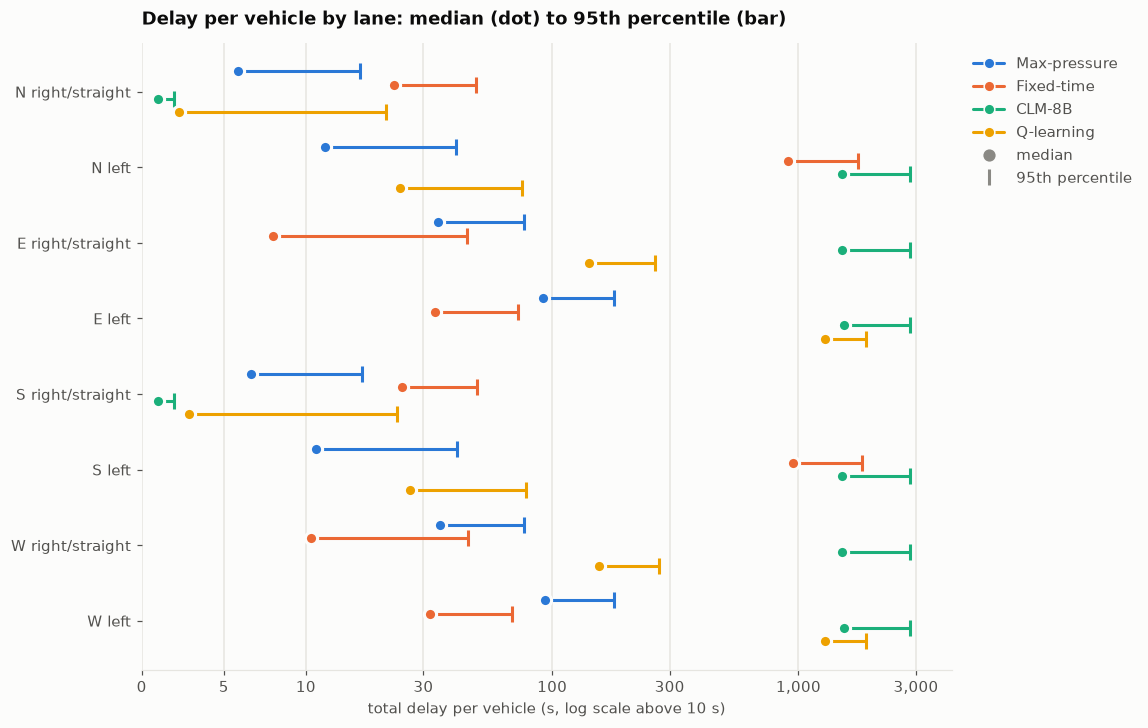

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 0.75 * len(LANE_ORDER) + 1.4))
band = 0.72
for i, lane in enumerate(LANE_ORDER):
    for j, a in enumerate(AGENTS):
        y = i + (j - (len(AGENTS) - 1) / 2) * band / len(AGENTS)
        x = vehicles[(vehicles["lane_name"] == lane) & (vehicles["controller"] == a)][METRIC]
        p50, p95 = np.percentile(x, 50), np.percentile(x, 95)
        ax.plot([p50, p95], [y, y], color=color(a), zorder=2)
        ax.scatter([p50], [y], s=64, color=color(a), edgecolors=SURFACE, linewidths=2, zorder=3)
        ax.scatter([p95], [y], marker="|", s=110, color=color(a), linewidths=2, zorder=3)

ax.set_yticks(range(len(LANE_ORDER)), LANE_ORDER)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xscale("symlog", linthresh=10, linscale=0.6)
ax.set_xlim(0, vehicles[METRIC].max() * 1.4)
ax.set_xticks([t for t in [0, 5, 10, 30, 100, 300, 1000, 3000, 10000] if t <= vehicles[METRIC].max() * 1.4])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel(f"{METRIC.replace('_', ' ')} per vehicle (s, log scale above 10 s)")
ax.set_title("Delay per vehicle by lane: median (dot) to 95th percentile (bar)")
handles = [Line2D([], [], color=color(a), marker="o", markersize=7, markeredgecolor=SURFACE, label=name(a)) for a in AGENTS]
handles += [Line2D([], [], color=INK_MUTED, marker="o", linestyle="", markersize=7, label="median"),
            Line2D([], [], color=INK_MUTED, marker="|", linestyle="", markersize=11, markeredgewidth=2, label="95th percentile")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), labelcolor=INK_2)
plt.show()

## Queues over time

Stopped vehicles on each incoming lane, sampled at every decision step. One panel per controller, same colour scale.
Vehicles that cannot enter the network are not on a lane yet, so a saturated lane is also a lane whose backlog grows (next chart).

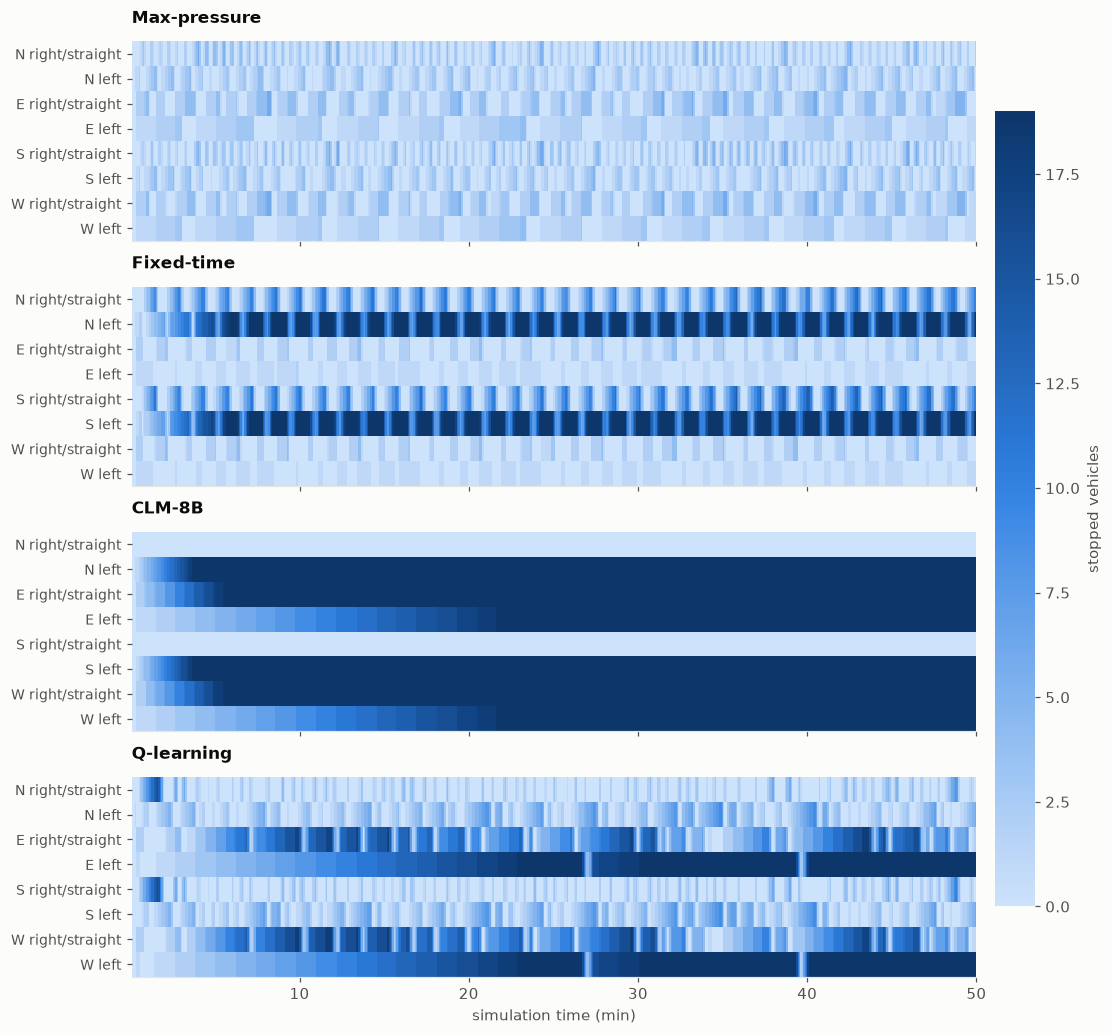

In [6]:
cmap = LinearSegmentedColormap.from_list("sequential_blue", BLUE_RAMP)
vmax = lanes["stopped"].max()
fig, axes = plt.subplots(len(AGENTS), 1, figsize=(10, 2.1 * len(AGENTS) + 0.9), sharex=True, constrained_layout=True, squeeze=False)
for ax, a in zip(axes[:, 0], AGENTS):
    grid = lanes[lanes["controller"] == a].pivot_table(index="lane_name", columns="step", values="stopped", aggfunc="sum")
    grid = grid.reindex(LANE_ORDER)
    steps = grid.columns.values / 60
    image = ax.imshow(grid.values, aspect="auto", cmap=cmap, vmin=0, vmax=vmax, interpolation="nearest",
                      extent=[steps.min(), steps.max(), len(LANE_ORDER) - 0.5, -0.5])
    ax.set_yticks(range(len(LANE_ORDER)), LANE_ORDER, fontsize=9)
    ax.set_title(name(a), fontsize=11)
    ax.grid(False)
axes[-1, 0].set_xlabel("simulation time (min)")
fig.colorbar(image, ax=axes[:, 0], label="stopped vehicles", shrink=0.85, pad=0.01).outline.set_visible(False)
plt.show()

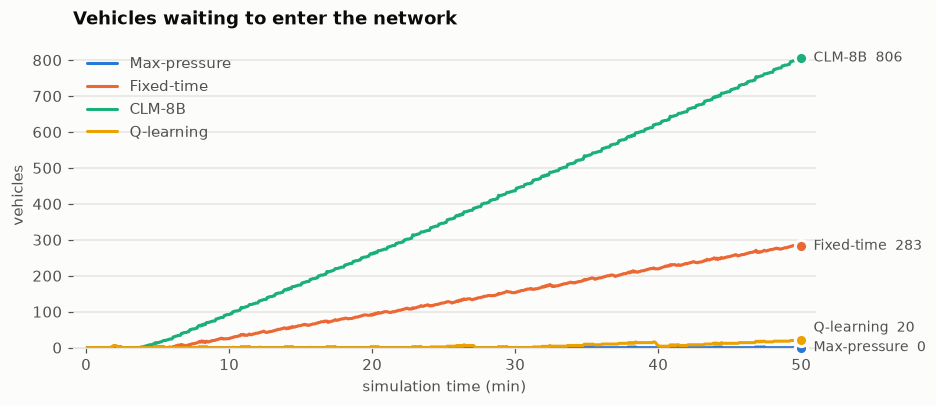

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ends = []
for a in AGENTS:
    m = metrics[metrics["controller"] == a]
    ax.plot(m["step"] / 60, m["system_total_backlogged"], color=color(a), label=name(a))
    x, y = m["step"].iloc[-1] / 60, m["system_total_backlogged"].iloc[-1]
    ends.append((x, y, f"{name(a)}  {y:,.0f}", color(a)))
ax.set_xlabel("simulation time (min)")
ax.set_ylabel("vehicles")
ax.set_ylim(bottom=0)
ax.grid(axis="x", visible=False)
ax.set_title("Vehicles waiting to enter the network")
ax.legend(loc="upper left", labelcolor=INK_2)
ax.margins(x=0.02)
plt.subplots_adjust(right=0.8)
end_labels(ax, ends)
plt.show()

## Which phases get green

Share of decision steps each phase was showing green (yellow = switching between phases).

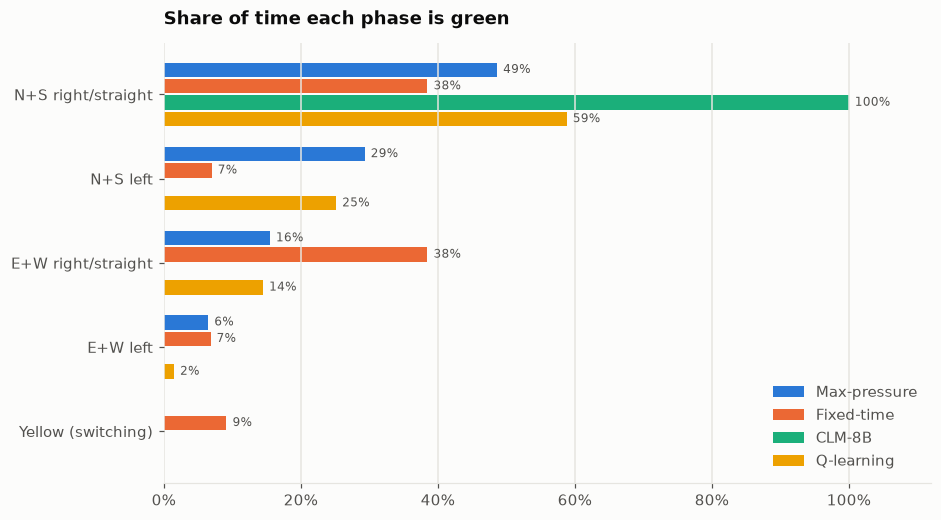

controller,Max-pressure,Fixed-time,CLM-8B,Q-learning
phase_name,,,,
N+S right/straight,48.7%,38.5%,100.0%,58.8%
N+S left,29.3%,7.0%,0.0%,25.2%
E+W right/straight,15.5%,38.5%,0.0%,14.5%
E+W left,6.5%,6.8%,0.0%,1.5%
Yellow (switching),0.0%,9.2%,0.0%,0.0%


In [8]:
share = signals.groupby("controller")["phase_name"].value_counts(normalize=True).unstack("controller").fillna(0)
rows = PHASE_ORDER + (["Yellow (switching)"] if "Yellow (switching)" in share.index else [])
share = share.reindex(rows).fillna(0)[AGENTS]

fig, ax = plt.subplots(figsize=(9, 0.8 * len(rows) + 1.2))
step = 0.78 / len(AGENTS)
for j, a in enumerate(AGENTS):
    y = np.arange(len(rows)) + (j - (len(AGENTS) - 1) / 2) * step
    ax.barh(y, share[a], height=step * 0.88, color=color(a), label=name(a))
    for yi, v in zip(y, share[a]):
        if v > 0:  # zero shares are in the table below
                ax.annotate(f"{v:.0%}", (v, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK_2)
ax.set_yticks(range(len(rows)), rows)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(0, min(1.12, share.values.max() * 1.15))
ax.set_title("Share of time each phase is green")
ax.legend(loc="lower right", labelcolor=INK_2)
plt.show()
share.rename(columns=name).style.format("{:.1%}")

## Drill into one lane

lanes: ['N right/straight', 'N left', 'E right/straight', 'E left', 'S right/straight', 'S left', 'W right/straight', 'W left']


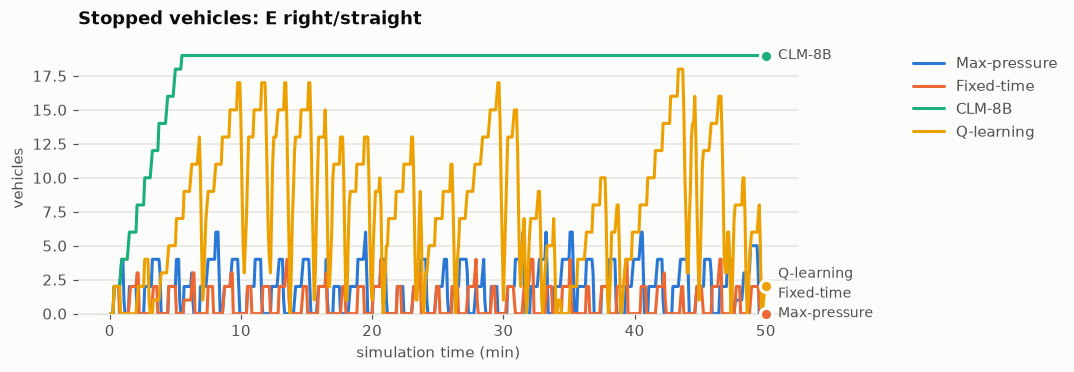

In [9]:
def plot_lane(lane_name):
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ends = []
    for a in AGENTS:
        d = lanes[(lanes["controller"] == a) & (lanes["lane_name"] == lane_name)]
        ax.plot(d["step"] / 60, d["stopped"], color=color(a), label=name(a))
        ends.append((d["step"].iloc[-1] / 60, d["stopped"].iloc[-1], name(a), color(a)))
    ax.set_title(f"Stopped vehicles: {lane_name}")
    ax.set_xlabel("simulation time (min)")
    ax.set_ylabel("vehicles")
    ax.set_ylim(bottom=0)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left", bbox_to_anchor=(1.14, 1), labelcolor=INK_2)
    plt.subplots_adjust(right=0.78)
    end_labels(ax, ends)
    plt.show()


print("lanes:", LANE_ORDER)
plot_lane(LANE_ORDER[2])

## Learning curve

Mean delay per vehicle in each run, for controllers that were run more than once (e.g. Q-learning with `-runs 30`).

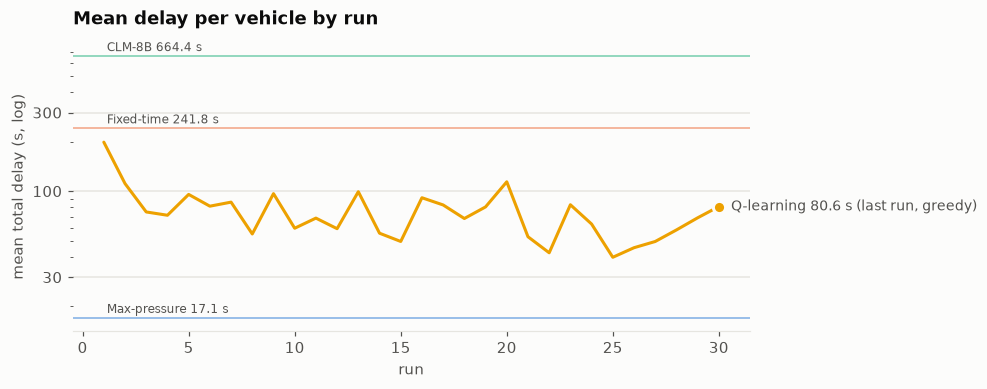

In [10]:
curves = {}
for a, folder in runs.items():
    v = pd.read_csv(folder / "vehicles.csv")
    if v["run"].nunique() > 1:
        curves[a] = v.groupby("run")[METRIC].agg(["mean", lambda x: np.percentile(x, 95)]).set_axis(["mean", "p95"], axis=1)

if curves:
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ends = []
    for a, c in curves.items():
        ax.plot(c.index, c["mean"], color=color(a), label=f"{name(a)} (mean)")
        ends.append((c.index[-1], c["mean"].iloc[-1], f"{name(a)} {c['mean'].iloc[-1]:,.1f} s (last run, greedy)", color(a)))
    for a in AGENTS:  # single-run controllers as reference levels
        if a not in curves:
            level = vehicles[vehicles["controller"] == a][METRIC].mean()
            ax.axhline(level, color=color(a), linewidth=1, alpha=0.6)
            ax.annotate(f"{name(a)} {level:,.1f} s", (1, level), xytext=(2, 3), textcoords="offset points", fontsize=8, color=INK_2)
    ax.set_yscale("log")
    top = max(ax.get_ylim()[1], 10)
    ax.set_yticks([t for t in [3, 10, 30, 100, 300, 1000, 3000] if ax.get_ylim()[0] <= t <= top])
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    ax.set_xlabel("run")
    ax.set_ylabel(f"mean {METRIC.replace('_', ' ')} (s, log)")
    ax.grid(axis="x", visible=False)
    ax.set_title("Mean delay per vehicle by run")
    plt.subplots_adjust(right=0.74)
    end_labels(ax, ends)
    plt.show()
    display(pd.concat({name(a): c for a, c in curves.items()}, axis=1).style.format("{:,.1f}"))
else:
    print("No controller with more than one run loaded.")

## CLM scores

How much the CLM's probability for each phase varies across decisions. Near-constant scores mean the model is not
responding to the traffic state.

In [11]:
if "clm" in AGENTS:
    s = signals[signals["controller"] == "clm"]
    scores = s[[c for c in s.columns if c.startswith("score_")]].dropna()
    scores.columns = PHASE_ORDER[: scores.shape[1]]
    display(scores.describe().T[["count", "mean", "std", "min", "max"]].style.format("{:.3f}", subset=["mean", "std", "min", "max"]))
else:
    print("No CLM run loaded.")

,count,mean,std,min,max
N+S right/straight,597.000000,0.338,0.012,0.291,0.375
N+S left,597.000000,0.244,0.011,0.215,0.284
E+W right/straight,597.000000,0.232,0.007,0.212,0.250
E+W left,597.000000,0.186,0.008,0.162,0.211
